In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import os

In [3]:
def Tm_model(T, I0, I1, Tm, slope):
    return I0 + (I1 - I0)/(1 + np.exp( (Tm-T)/slope) )

def Tm_model_scaled(T, Tm, slope):
    return  1/(1 + np.exp( (Tm-T)/slope) )

In [7]:
df1 = pd.read_csv('Tm_Kristoffer.csv')
df1


,Temp,WS-An,WS-Ac,WS-Pyr,MS9-An,MS9-Ac,MS10-An,MS10-Pyr,MS12-An
0,90,85645850880,4.079950e+11,5.582200e+11,35807294464,3.047950e+11,71931523072,5.267610e+11,1.185830e+11
1,85,86333993472,4.036250e+11,5.789310e+11,21430672128,1.988340e+11,89612329984,5.275730e+11,1.095340e+11
2,80,85099401728,4.045350e+11,5.847470e+11,8210070528,1.617060e+11,86915972096,5.388150e+11,4.076443e+10
3,75,73670639104,3.888220e+11,5.951150e+11,7670443008,1.415570e+11,79000642048,5.592510e+11,2.161945e+10
4,70,63538511872,3.544530e+11,5.701110e+11,5526214656,1.264830e+11,69174344704,5.639660e+11,1.369729e+10
5,65,46187424768,2.679430e+11,4.693850e+11,4480771072,1.069040e+11,58090542080,5.446790e+11,9.853456e+09
6,60,20126299136,1.447690e+11,2.835410e+11,2020781056,9.683714e+10,31983441920,4.787850e+11,6.351522e+09
7,55,11630501888,9.299140e+10,1.902460e+11,2231019520,8.631430e+10,17469296640,3.451630e+11,3.775844e+09
8,50,6745078784,6.439289e+10,1.364710e+11,1580951552,7.111280e+10,5677572096,2.102790e+11,9.796035e+08
9,45,1563276288,4.464209e+10,1.021730e+11,1542957056,6.247022e+10,-85151744,1.404570e+11,5.450342e+08


In [8]:
df2 = pd.read_csv('Tm_WT_dK_dI.csv')
df2

,T,WT,dGumK,dGumI
0,25,5.050677e+09,2.795522e+10,9.417519e+10
1,40,1.191828e+10,2.533919e+10,1.070440e+11
2,45,9.981992e+09,2.773286e+10,1.221973e+11
3,50,1.437741e+10,2.801786e+10,1.538137e+11
4,55,1.829413e+10,2.665501e+10,1.564233e+11
5,60,2.826445e+10,2.979687e+10,1.663549e+11
6,65,3.793369e+10,2.788120e+10,1.510532e+11
7,70,5.424507e+10,3.051329e+10,1.900146e+11
8,75,7.310539e+10,2.834028e+10,1.887328e+11
9,80,1.022301e+11,3.475667e+10,1.850211e+11


<>:4: SyntaxWarning: invalid escape sequence '\D'
<>:4: SyntaxWarning: invalid escape sequence '\D'
<>:4: SyntaxWarning: invalid escape sequence '\D'
<>:4: SyntaxWarning: invalid escape sequence '\D'
<>:4: SyntaxWarning: invalid escape sequence '\D'
<>:4: SyntaxWarning: invalid escape sequence '\D'
<>:4: SyntaxWarning: invalid escape sequence '\D'
<>:7: SyntaxWarning: invalid escape sequence '\D'
<>:7: SyntaxWarning: invalid escape sequence '\D'
<>:47: SyntaxWarning: invalid escape sequence '\c'
<>:4: SyntaxWarning: invalid escape sequence '\D'
<>:4: SyntaxWarning: invalid escape sequence '\D'
<>:4: SyntaxWarning: invalid escape sequence '\D'
<>:4: SyntaxWarning: invalid escape sequence '\D'
<>:4: SyntaxWarning: invalid escape sequence '\D'
<>:4: SyntaxWarning: invalid escape sequence '\D'
<>:4: SyntaxWarning: invalid escape sequence '\D'
<>:7: SyntaxWarning: invalid escape sequence '\D'
<>:7: SyntaxWarning: invalid escape sequence '\D'
<>:47: SyntaxWarning: invalid escape sequence '\c

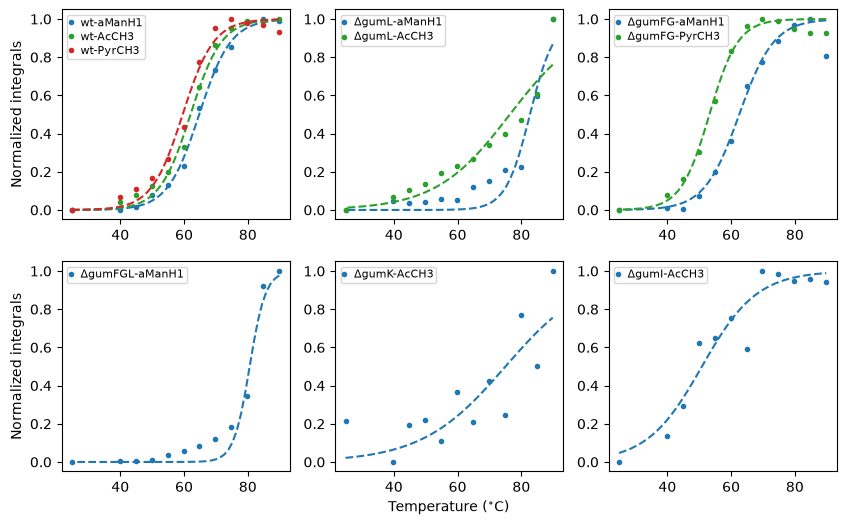

In [44]:
# add mosaic sublots
fig, axs = plt.subplot_mosaic([['A', 'B', 'C'], ['D', 'E', 'F']], figsize=(10, 6))
COLORS1 = ['tab:blue','tab:green','tab:red','tab:blue','tab:green','tab:blue','tab:green','tab:blue', 'tab:blue', 'tab:blue']
LABELS1 = ['wt-aManH1', 'wt-AcCH3', 'wt-PyrCH3','$\Delta$gumL-aManH1', '$\Delta$gumL-AcCH3','$\Delta$gumFG-aManH1', '$\Delta$gumFG-PyrCH3', '$\Delta$gumFGL-aManH1', '$\Delta$gumK-AcCH3', '$\Delta$gumI-AcCH3'] 
#generate a dictionary of col name to subplot, start with WS goes to A, Start with MS9 goes to B, Start with MS10 goes to C, Start with MS12 goes to D
COLORS2 = ['','tab:blue','tab:blue']
LABELS2 = ['','$\Delta$gumK-AcCH3', '$\Delta$gumI-AcCH3'] 

x = df1['Temp'] - 0.15 # correct K to C conversion
x_model = np.linspace(x.values[0], x.values[-1], num=50)

for i,c in enumerate(df1.columns[1:]):
    y = df1[c]
    y = (y - y.min())/(y.max() - y.min())
    guesses = [50, 1.0]
    popt, pcov = curve_fit(Tm_model_scaled, x, y, p0 = guesses)
    perr = np.sqrt(np.diag(pcov))
    #print("{}: {:.1f} +/- {:.1f}".format(c,popt[0],perr[1]))
    if c.startswith('WS'):
        ax = axs['A']
        ax.set_ylabel('Normalized integrals')
    elif c.startswith('MS9'):
        ax = axs['B']
    elif c.startswith('MS10'):
        ax = axs['C']
    elif c.startswith('MS12'):
        ax = axs['D']
        ax.set_ylabel('Normalized integrals')

    ax.plot(x,y, '.', color=COLORS1[i], label=LABELS1[i])
    ax.plot(x_model, Tm_model_scaled(x_model, *popt), '--', color=COLORS1[i])
    ax.legend(fontsize=8,borderpad=0.2,labelspacing=0.2, handlelength=0.2)
    #plt.title('{} Tm = {:.1f} +/- {:.1f}   slope = {:.1f}'.format(c, popt[2], perr[2], popt[3]))

x = df2['T'] - 0.15 # correct K to C conversion
x_model = np.linspace(x.values[0], x.values[-1], num=50)

for i,c in enumerate(df2.columns[1:]):
    y = df2[c]
    y = (y - y.min())/(y.max() - y.min())
    guesses = [50, 1.0]
    popt, pcov = curve_fit(Tm_model_scaled, x, y, p0 = guesses)
    perr = np.sqrt(np.diag(pcov))
    #print("{}: {:.1f} +/- {:.1f}".format(c,popt[0],perr[1]))
    if c.startswith('dGumK'):
        ax = axs['E']
        ax.set_xlabel('Temperature ($^{\circ}$C)')
    elif c.startswith('dGumI'):
        ax = axs['F']
    else:
        continue
    ax.plot(x,y, '.', color=COLORS2[i], label=LABELS2[i])
    ax.plot(x_model, Tm_model_scaled(x_model, *popt), '--', color=COLORS2[i])
    ax.legend(fontsize=8,borderpad=0.2,labelspacing=0.2, handlelength=0.2)
    #plt.title('{} Tm = {:.1f} +/- {:.1f}   slope = {:.1f}'.format(c, popt[2], perr[2], popt[3]))


plt.savefig('all_Tm_fits.png', dpi=300)
plt.show()
        